In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

In [2]:
df = pd.read_csv('california_housing_with_target.csv')

In [3]:
features = ["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "Latitude", "Longitude"]

x_data = df[features].values
x_mean = x_data.mean(axis=0)
x_std = x_data.std(axis=0)
x_scaled = (x_data - x_mean) / x_std

x = torch.tensor(x_scaled, dtype=torch.float32)
y = torch.tensor(df["MedHouseVal"].values, dtype=torch.float32).view(-1, 1)

epoch = 100000
lr = 0.01
loss = []
w = torch.randn(x.shape[1], 1, requires_grad=True)
b = torch.randn(1, requires_grad=True)
for i in range(epoch):
    yhat = x @ w + b
    l = torch.mean((yhat - y) ** 2)
    loss.append(l.item())
    l.backward()
    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_()
    b.grad.zero_()

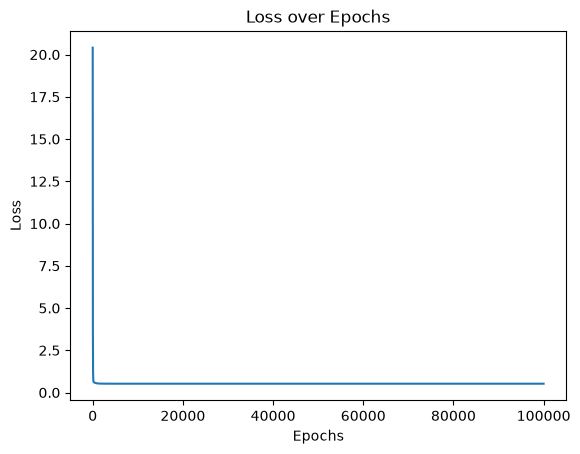

In [4]:
plt.plot(loss)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss over Epochs')
plt.show()

In [5]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(df[features], df["MedHouseVal"])

my_w_original = w.detach().numpy().ravel() / x_std
my_b_original = b.detach().numpy().item() - np.sum(my_w_original * x_mean)

my_predictions = df[features].values @ my_w_original + my_b_original
sklearn_predictions = model.predict(df[features])

print("My w (original):", my_w_original)
print("My b (original):", my_b_original)
print("Sklearn w:", model.coef_)
print("Sklearn b:", model.intercept_)
print("My loss:", np.mean((my_predictions - df["MedHouseVal"].values) ** 2))
print("Sklearn loss:", np.mean((sklearn_predictions - df["MedHouseVal"].values) ** 2))

My w (original): [ 4.36700595e-01  9.43600133e-03 -1.07331646e-01  6.45106485e-01
 -3.97568310e-06 -3.78659990e-03 -4.21299085e-01 -4.34498182e-01]
My b (original): -36.94063711389095
Sklearn w: [ 4.36693293e-01  9.43577803e-03 -1.07322041e-01  6.45065694e-01
 -3.97638942e-06 -3.78654265e-03 -4.21314378e-01 -4.34513755e-01]
Sklearn b: -36.94192020718444
My loss: 0.5243209863657919
Sklearn loss: 0.5243209861846072
